<h1 style="font-size: 60px; font-weight: bold; background: linear-gradient(90deg, #fff700, #ff3b00); -webkit-background-clip: text; -webkit-text-fill-color: transparent; text-shadow: 0 0 12px rgba(255, 215, 0, 0.8);">HEART DISEASE RISK PREDICTION</h1>

<h2 style="font-size: 40px; font-weight: bold; background: linear-gradient(90deg, #ff69b4, #ff1744); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">METADATA</h2>

## Dataset Overview

- The dataset contains **920 patient records** and **16 columns**.
- It includes demographic information and medical measurements related to heart health.
- Records come from four source groups:
    - **Cleveland:** 304 records
    - **Hungary:** 293 records
    - **Switzerland:** 123 records
    - **VA Long Beach:** 200 records
- Recorded information includes:
    - Age and sex
    - Chest pain type
    - Resting blood pressure and cholesterol
    - Maximum heart rate
    - Disease status

## Dataset Features

The dataset contains the following columns:

- **id:** Record identification number.
- **age:** Patient's age in years.
- **sex:** Recorded sex of the patient.
- **dataset:** Source group of the record.
- **cp:** Type of chest pain.
- **trestbps:** Resting blood pressure.
- **chol:** Serum cholesterol level.
- **fbs:** Indicates whether fasting blood sugar is greater than 120 mg/dL.
- **restecg:** Resting electrocardiogram category.
- **thalch:** Maximum heart rate achieved.
- **exang:** Indicates exercise-induced angina.
- **oldpeak:** ST depression during exercise compared with rest.
- **slope:** Slope of the ST segment during peak exercise.
- **ca:** Number of major vessels identified by fluoroscopy.
- **thal:** Recorded thalassemia-related test category.
- **num:** Original disease-status or extent variable.

### Import libraries


In [1]:
# import libraries

# 1. to handle the data
import pandas as pd
import numpy as np

# to visualize the dataset
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# To preprocess the data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer, KNNImputer
# import iterative imputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# machine learning
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
#for classification tasks
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, RandomForestRegressor
from xgboost import XGBClassifier
#metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

# ignore warnings   
import warnings
warnings.filterwarnings('ignore')


### Load the dataset



In [2]:
import pandas as pd
df=pd.read_csv("heart_disease_uci.csv")

In [3]:
# print the first five rows of dataFrame
df.head(5)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## Exploratory Data Analysis
### Explore each column


In [4]:
# exploring the data type of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [5]:
df.shape

(920, 16)

In [6]:
# id column
df['id'].min(),df['id'].max()


(np.int64(1), np.int64(920))

In [7]:
# age column
int(df['age'].min()), int(df['age'].max())

(28, 77)

<Axes: xlabel='age', ylabel='Count'>

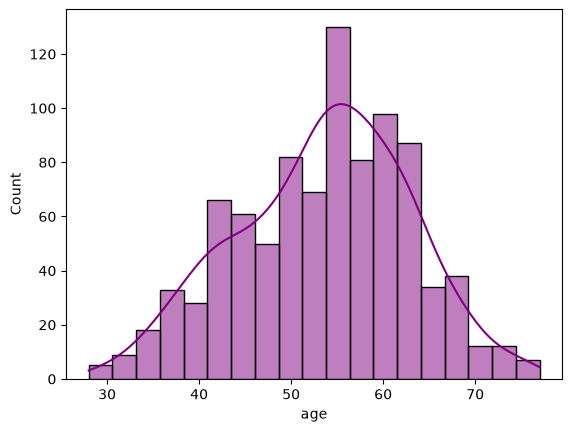

In [8]:
# draw a histogram to see the distribution of age column
sns.histplot(df["age"],kde="true",color="purple")

In [9]:
import plotly.express as px
import plotly.io as pio

fig = px.histogram(
    data_frame=df,
    x="age",
    color="sex"
)

fig.show()

In [10]:
# find the values of sex column
df['sex'].value_counts()

sex
Male      726
Female    194
Name: count, dtype: int64

In [11]:
# calculate the percentage of male and female value counts in the data
male_count=726
female_count=194
total_count=male_count+female_count

# calculate percentages
male_percentage=(male_count/total_count)*100
female_percentage=(female_count/total_count)*100

# display the results
print(f"Male percentage in data:{male_percentage:.2f}%")
print(f"Female percentage in data:{female_percentage:.2f}%")

# difference
difference_percentage=((male_count-female_count)/female_count)*100
print(f"males are:{difference_percentage:.2f}% more than females in the data")

Male percentage in data:78.91%
Female percentage in data:21.09%
males are:274.23% more than females in the data


In [12]:
# find the value counts

#### Dataset column

In [13]:
# find the unique values in dataset column
df["dataset"].unique()

<ArrowStringArray>
['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
Length: 4, dtype: str

In [14]:
# find unique values count i dataset column
df["dataset"].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [15]:
fig = px.histogram(
    df,
    x="dataset",
    color="sex",
    barmode="group"
)

fig.show()

# print the values count of dataset column grouped by sex column
print(df.groupby("sex")["dataset"].value_counts())

sex     dataset      
Female  Cleveland         97
        Hungary           81
        Switzerland       10
        VA Long Beach      6
Male    Hungary          212
        Cleveland        207
        VA Long Beach    194
        Switzerland      113
Name: count, dtype: int64


In [16]:
# make a plot of age column grouped by age column
fig = px.histogram(df, x="age", color="dataset")
fig.show()

# print the mean median and mode of age column grouped by dataset column
print(f"Mean of data set:{df.groupby('dataset')['age'].mean()}")
print("--------------------------------")
print(f"Median of data set:{df.groupby('dataset')['age'].median()}")
print("--------------------------------")
print(f"Mode of data set:{df.groupby('dataset')['age'].agg(pd.Series.mode)}")
print("--------------------------------")

Mean of data set:dataset
Cleveland        54.351974
Hungary          47.894198
Switzerland      55.317073
VA Long Beach    59.350000
Name: age, dtype: float64
--------------------------------
Median of data set:dataset
Cleveland        55.5
Hungary          49.0
Switzerland      56.0
VA Long Beach    60.0
Name: age, dtype: float64
--------------------------------
Mode of data set:dataset
Cleveland              58
Hungary                54
Switzerland            61
VA Long Beach    [62, 63]
Name: age, dtype: object
--------------------------------


#### cp(chest pain) column

In [17]:
# value counts of cp column
df['cp'].value_counts()

cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64

In [18]:
# draw the plot of age column grouped by cp column
fig = px.histogram(df, x="age", color="cp")
fig.show()

<Axes: xlabel='cp', ylabel='count'>

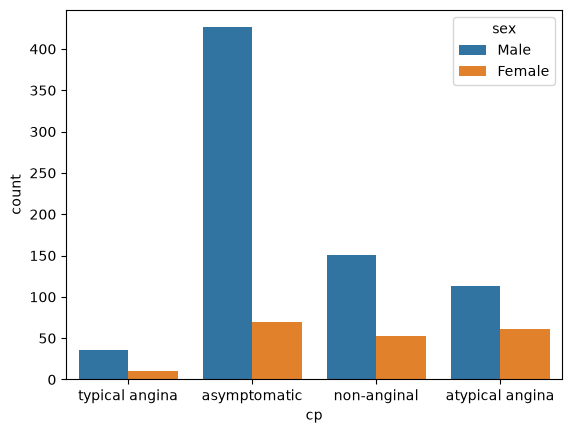

In [19]:
# count plot of cp column by sex column
sns.countplot(x="cp",hue="sex",data=df)

<Axes: xlabel='cp', ylabel='count'>

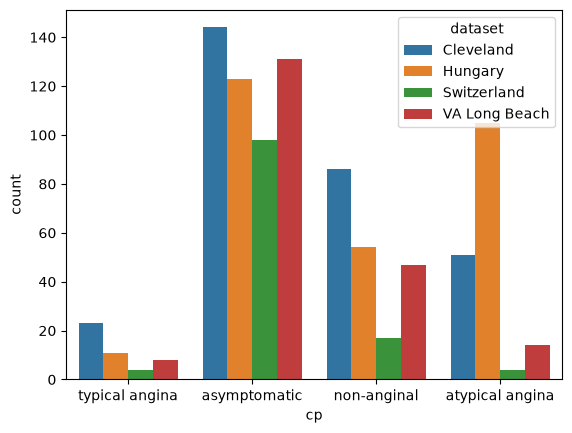

In [20]:
# count plot of cp column by dataset column
sns.countplot(df,x="cp",hue="dataset")

<h4 style="color: peachpuff; font-size: 40px; font-weight: bold;">trestbps (resting blood pressure) column</h4>

<p style="color: lightgreen; font-size: 25px;">
    High blood pressure can strain the heart and blood vessels, increasing the risk of heart disease and stroke. Low blood pressure may cause dizziness, weakness, and poor blood flow to vital organs. We can bin the data into categories such as normal, low, and high to analyze how blood pressure relates to heart disease risk.
</p>


In [21]:
# summary of trestbps column
df['trestbps'].describe()

count    861.000000
mean     132.132404
std       19.066070
min        0.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64

<Axes: xlabel='trestbps', ylabel='Count'>

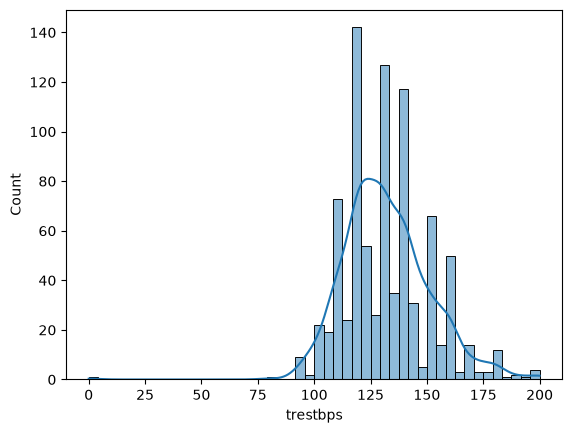

In [22]:
# create a histogram of trestbps column
sns.histplot(df['trestbps'], kde=True)

<h1 style="color: pink; font-size: 60px; font-weight: bold;">Dealing with missing values</h1>

In [23]:
categorical_cols = ['thal', 'ca', 'slope', 'exang', 'restecg','fbs', 'cp', 'sex', 'num']
bool_cols = ['fbs', 'exang']
numeric_cols = ['oldpeak', 'thalch', 'chol', 'trestbps', 'age']
categorical_cols

['thal', 'ca', 'slope', 'exang', 'restecg', 'fbs', 'cp', 'sex', 'num']

In [24]:
# dealing with missing values trestbps column
# find the percentage of missing values in trestbps column
missing_values_count = df['trestbps'].isnull().sum()/len(df) * 100
print(f"Percentage of missing values in trestbps column: {missing_values_count:.2f}%")

Percentage of missing values in trestbps column: 6.41%


In [25]:
# impute the missing values in trestbps column using iterative imputer
# create an object of iterative imputer
imputer = IterativeImputer(max_iter=10, random_state=42)

# fit the imputer on the trestbps column
imputer.fit(df[['trestbps']])
# transform the data
df['trestbps'] = imputer.transform(df[['trestbps']])

# check the missing values in trestbps column
missing_values_count_after_imputation = df['trestbps'].isnull().sum()
print(f"Percentage of missing values in trestbps column after imputation: {missing_values_count_after_imputation:.2f}%")

Percentage of missing values in trestbps column after imputation: 0.00%


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  920 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [27]:
# impute missing values using iterative imputer for thalach,ca,oldpeak,chol columns 
# create an object of iterative imputer
imputer_2 = IterativeImputer(max_iter=10, random_state=42)
# fit_transforms the imputer on ca,oldpeak,thalach,chol columns separately 
df['ca']=imputer_2.fit_transform(df[['ca']])
df['oldpeak']=imputer_2.fit_transform(df[['oldpeak']])
df['thalch'] =imputer_2.fit_transform(df[['thalch']])  
df['chol']=imputer_2.fit_transform(df[['chol']])  
df['fbs']=imputer_2.fit_transform(df[['fbs']]) 
df['exang']=imputer_2.fit_transform(df[['exang']]) 




In [28]:
# lets impute other columns with missing values
(df.isnull().sum()/len(df)*100).sort_values(ascending=False)

thal        52.826087
slope       33.586957
restecg      0.217391
id           0.000000
cp           0.000000
age          0.000000
sex          0.000000
dataset      0.000000
fbs          0.000000
chol         0.000000
trestbps     0.000000
thalch       0.000000
oldpeak      0.000000
exang        0.000000
ca           0.000000
num          0.000000
dtype: float64

In [29]:
# Fill missing categorical values using mode

for col in ['thal', 'slope', 'restecg']:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values again
print(df.isnull().sum())

id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [30]:
df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False)
missing_data_cols = df.isnull().sum()[df.isnull().sum() > 0].index.tolist()
missing_data_cols

[]

<h3 style="color: yellow; font-weight: bold;">Outliers</h3>

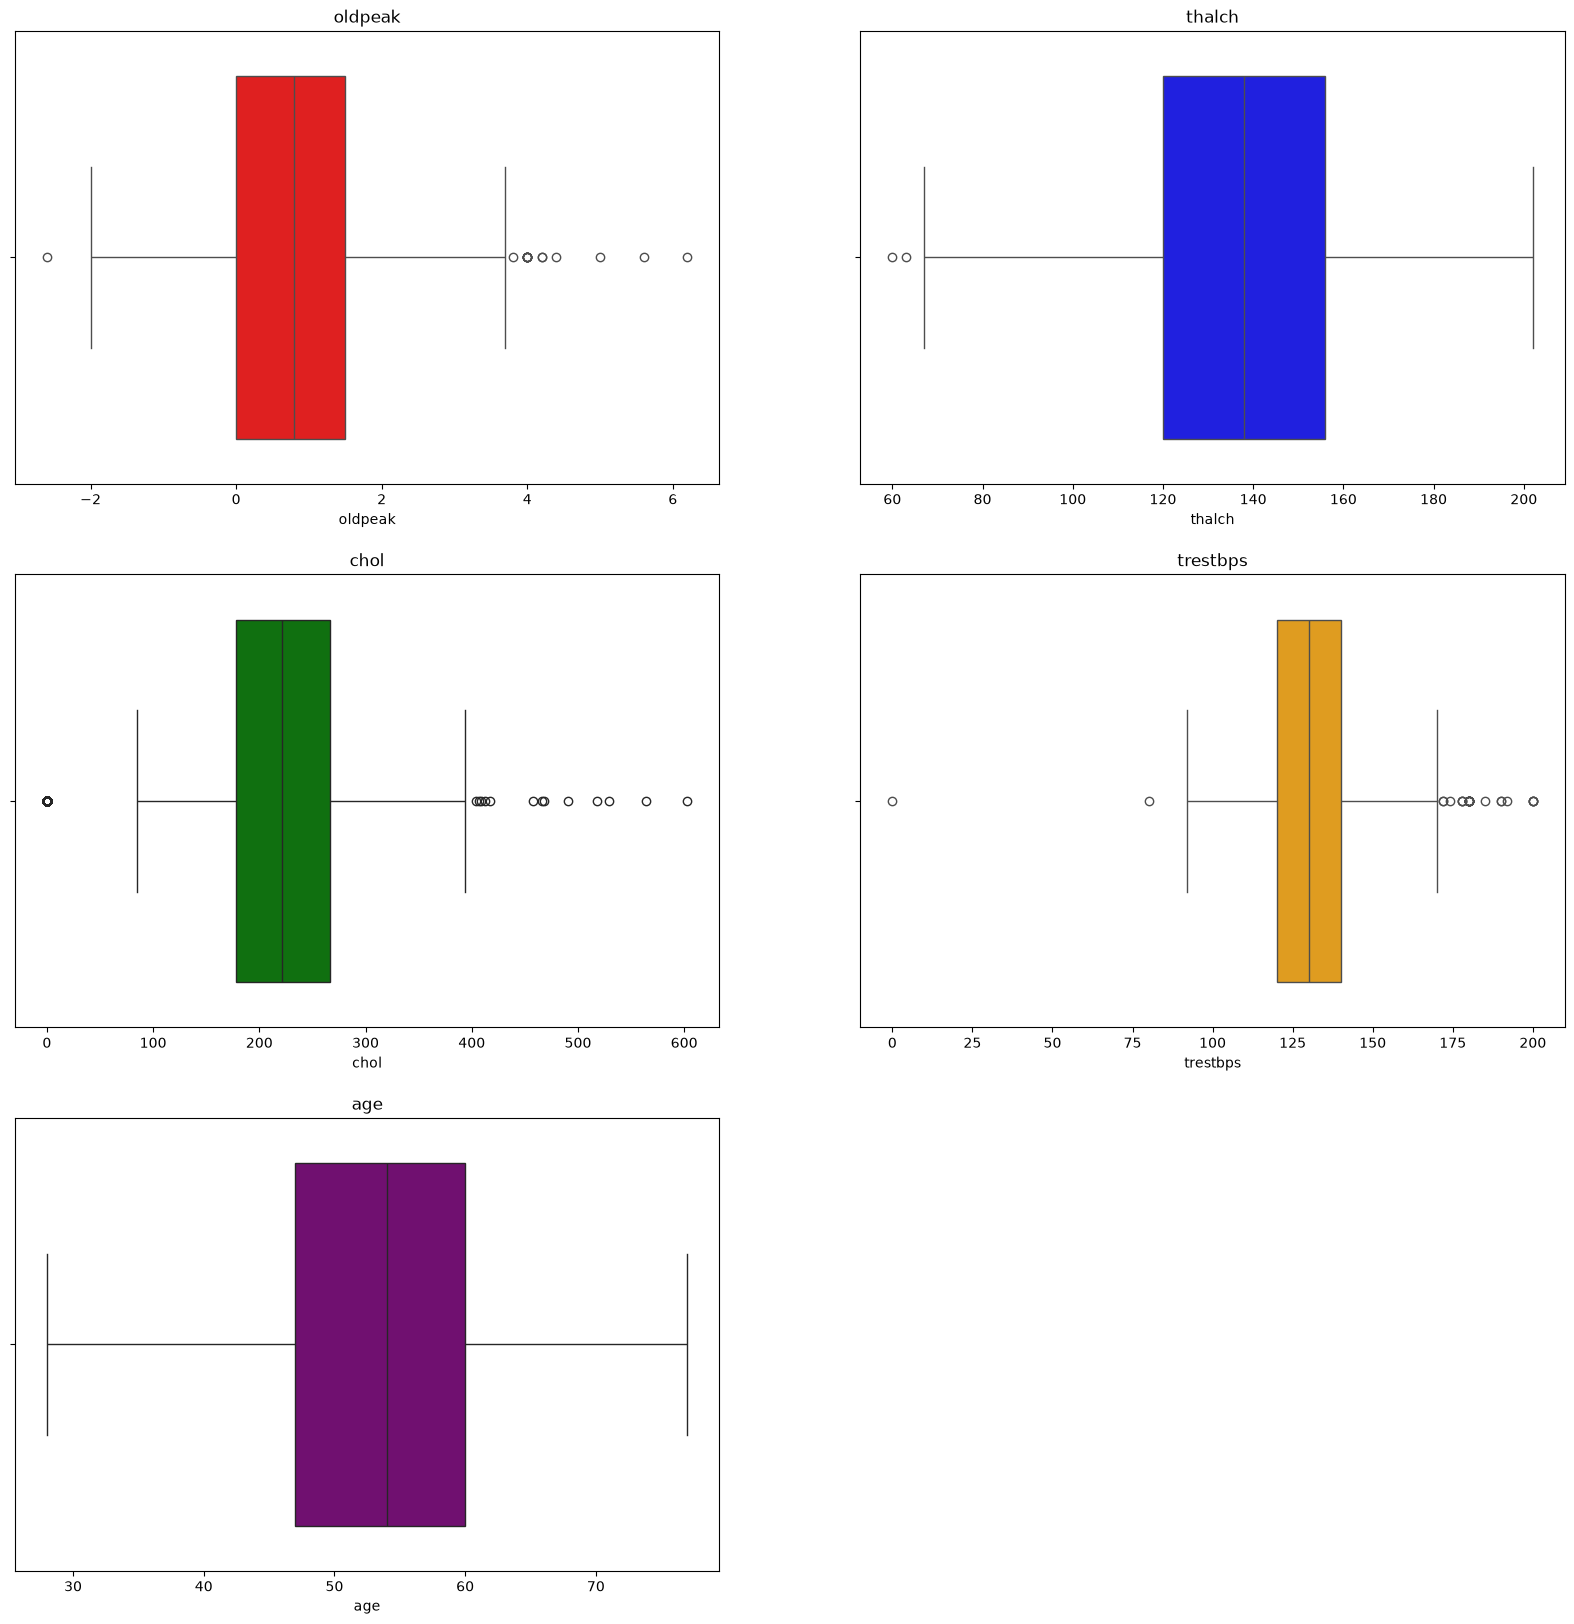

In [31]:
# create box plots fo all numeric columns using for loop and subplots
plt.figure(figsize=(20, 20))
colors=['red','blue','green','orange','purple']
for i, col in enumerate(numeric_cols):
    plt.subplot(3, 2, i+1)
    sns.boxplot(x=df[col], color=colors[i])
    plt.title(col)

plt.show()

In [32]:
# prin the row from df where trestbps value is zero
df[df['trestbps'] == 0]
# remove the row from df where trestbps value is zero
df = df[df['trestbps'] != 0]

In [33]:
df_box = df[numeric_cols].melt(var_name="column", value_name="value")
fig = px.box(
    df_box,
    x="column",
    y="value",
    color="column",
    title="Box plots of numeric columns"
)
fig.update_layout(width=1100, height=700, showlegend=False)
fig.show()

In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 919 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        919 non-null    int64  
 1   age       919 non-null    int64  
 2   sex       919 non-null    str    
 3   dataset   919 non-null    str    
 4   cp        919 non-null    str    
 5   trestbps  919 non-null    float64
 6   chol      919 non-null    float64
 7   fbs       919 non-null    float64
 8   restecg   919 non-null    str    
 9   thalch    919 non-null    float64
 10  exang     919 non-null    float64
 11  oldpeak   919 non-null    float64
 12  slope     919 non-null    str    
 13  ca        919 non-null    float64
 14  thal      919 non-null    str    
 15  num       919 non-null    int64  
dtypes: float64(7), int64(3), str(6)
memory usage: 167.7 KB


<h3 style="display: inline-block; width: fit-content; color: #ff69b4; font-weight: bold; background: linear-gradient(90deg, #ffe4f1, #87ceeb); padding: 12px 20px; border-radius: 8px; margin: 0;">
    Machine Learning
</h3>

In [35]:
df.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')

In [36]:
df['num'].value_counts()

num
0    411
1    265
2    109
3    106
4     28
Name: count, dtype: int64

#### Target column: `num`

The `num` column is the target variable used to predict heart disease. 





## Features,training and model selection

In [37]:
# split the data into x and y 
X = df.drop('num', axis=1) 
y = df['num']

# encode X data using seperate label encoder for all categorical columns and save it for inverse transform later
label_encoder=LabelEncoder()

for col in X.columns:
    if X[col].dtype == 'object' or X[col].dtype == 'category':
        X[col] = label_encoder.fit_transform(X[col])
    else:
        pass

# split the data into train and test 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Enlist all the models that will be used to predict heart disease
1. Logistic Regression

2. K-Nearest Neighbors (KNN)

3. Naive Bayes (NB)

4. Support Vector Machine (SVM)

5. Decision Tree

6. Random Forest

7. XGBoost

8. LightGBM

9. AdaBoost

10. Gradient Boosting


In [38]:
# import all models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB


# impot pipeline
from sklearn.pipeline import Pipeline

# import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [39]:
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# 1. X, y 
data = df.copy()
y = (data["num"] > 0).astype(int)
X = data.drop(columns=["num", "id", "dataset"], errors="ignore")

# 2. deal with fake zeros as missing values
for c in ["chol", "trestbps"]:
    X[c] = X[c].replace(0, np.nan)

# 3. Preprocessing (imputer + scaler + one-hot), all inside Pipeline
cat_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
X[cat_cols] = X[cat_cols].astype(str)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=42)

# 4. Tuning: own grid for each model
search = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
        {"m__C": [0.01, 0.1, 1, 10]}),
    "SVC": (SVC(probability=True, random_state=42),
        {"m__C": [0.1, 1, 10], "m__gamma": ["scale", 0.01, 0.1]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
        {"m__n_estimators": [200, 400], "m__max_depth": [4, 6, 10, None],
         "m__min_samples_leaf": [1, 3, 5]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"m__n_estimators": [100, 200], "m__learning_rate": [0.03, 0.05, 0.1],
         "m__max_depth": [2, 3]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=42),
        {"m__n_estimators": [100, 200], "m__max_depth": [2, 3, 4],
         "m__learning_rate": [0.03, 0.05, 0.1]}),
    "KNN": (KNeighborsClassifier(), {"m__n_neighbors": [5, 7, 9, 11, 15]}),
}

results, fitted = [], {}
for name, (est, grid) in search.items():
    pipe = Pipeline([("prep", prep), ("m", est)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    fitted[name] = gs
    results.append([name, gs.best_score_, gs.best_params_])
    print(f"{name}: CV F1 = {gs.best_score_:.3f}")

# 5. best fitted model
best_name = max(fitted, key=lambda n: fitted[n].best_score_)
best_model = fitted[best_name].best_estimator_
pred = best_model.predict(X_test)
print("\nWinner:", best_name, fitted[best_name].best_params_)
print("Test Accuracy:", round(accuracy_score(y_test, pred), 3))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

Logistic Regression: CV F1 = 0.845
SVC: CV F1 = 0.850
Random Forest: CV F1 = 0.853
Gradient Boosting: CV F1 = 0.844
XGBoost: CV F1 = 0.848
KNN: CV F1 = 0.834

Winner: Random Forest {'m__max_depth': 6, 'm__min_samples_leaf': 1, 'm__n_estimators': 200}
Test Accuracy: 0.837
[[62 20]
 [10 92]]
              precision    recall  f1-score   support

           0       0.86      0.76      0.81        82
           1       0.82      0.90      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



In [40]:
print(y.value_counts())
print(X.dtypes)
print(X.head())
print(X.isnull().sum().sum(), "missing values")

num
1    508
0    411
Name: count, dtype: int64
age           int64
sex             str
cp              str
trestbps    float64
chol        float64
fbs         float64
restecg         str
thalch      float64
exang       float64
oldpeak     float64
slope           str
ca          float64
thal            str
dtype: object
   age     sex               cp  trestbps   chol  fbs         restecg  thalch  \
0   63    Male   typical angina     145.0  233.0  1.0  lv hypertrophy   150.0   
1   67    Male     asymptomatic     160.0  286.0  0.0  lv hypertrophy   108.0   
2   67    Male     asymptomatic     120.0  229.0  0.0  lv hypertrophy   129.0   
3   37    Male      non-anginal     130.0  250.0  0.0          normal   187.0   
4   41  Female  atypical angina     130.0  204.0  0.0  lv hypertrophy   172.0   

   exang  oldpeak        slope   ca               thal  
0    0.0      2.3  downsloping  0.0       fixed defect  
1    1.0      1.5         flat  3.0             normal  
2    1.0      2.6   

In [41]:
y = (y > 0).astype(int)   # 0 = healthy, 1 = heart disease
print(y.value_counts())

num
1    508
0    411
Name: count, dtype: int64


In [42]:
df.info()

<class 'pandas.DataFrame'>
Index: 919 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        919 non-null    int64  
 1   age       919 non-null    int64  
 2   sex       919 non-null    str    
 3   dataset   919 non-null    str    
 4   cp        919 non-null    str    
 5   trestbps  919 non-null    float64
 6   chol      919 non-null    float64
 7   fbs       919 non-null    float64
 8   restecg   919 non-null    str    
 9   thalch    919 non-null    float64
 10  exang     919 non-null    float64
 11  oldpeak   919 non-null    float64
 12  slope     919 non-null    str    
 13  ca        919 non-null    float64
 14  thal      919 non-null    str    
 15  num       919 non-null    int64  
dtypes: float64(7), int64(3), str(6)
memory usage: 167.7 KB


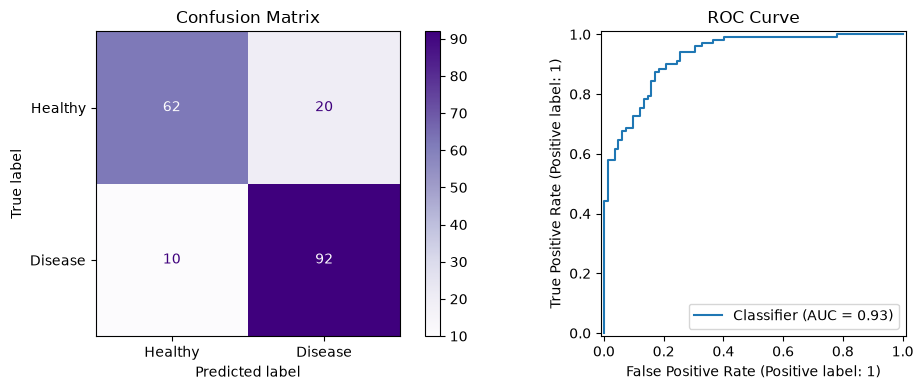

ROC-AUC: 0.927


In [43]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
import matplotlib.pyplot as plt

y_prob = best_model.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Purples", ax=ax[0],
    display_labels=["Healthy", "Disease"])
ax[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
ax[1].set_title("ROC Curve")
plt.tight_layout(); plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

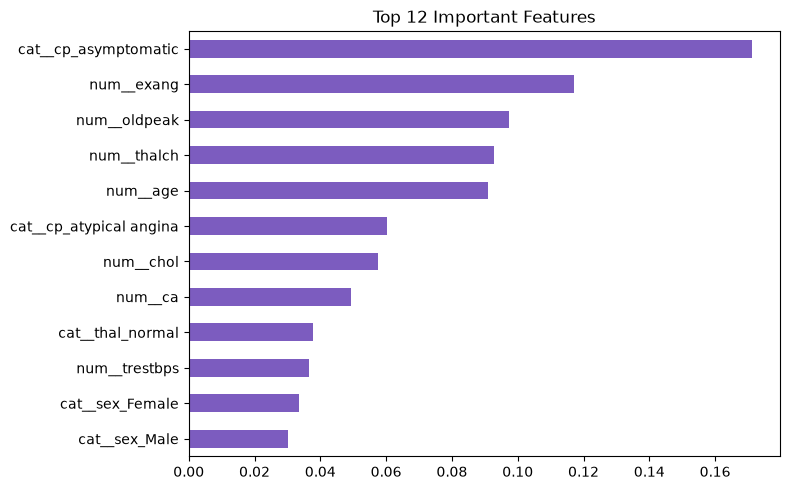

In [44]:
rf = best_model.named_steps["m"]
names = best_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names).sort_values().tail(12)
imp.plot(kind="barh", figsize=(8, 5), color="#7c5cbf")
plt.title("Top 12 Important Features"); plt.tight_layout(); plt.show()

In [45]:
import joblib
joblib.dump(best_model, "heart_model.pkl")

loaded = joblib.load("heart_model.pkl")
sample = X_test.iloc[[0]]
print("Prediction:", "heart Disease" if loaded.predict(sample)[0] == 1 else "Healthy")
print("Risk:", round(loaded.predict_proba(sample)[0][1] * 100, 1), "%")


Prediction: Healthy
Risk: 44.2 %


In [46]:
new_patient = pd.DataFrame([{
    "age": 55,
    "sex": "Male",
    "cp": "typical angina",
    "trestbps": 140,
    "chol": 230,
    "fbs": False,
    "restecg": "normal",
    "thalch": 150,
    "exang": False,
    "oldpeak": 1.5,
    "slope": "flat",
    "ca": 1,
    "thal": "normal",
}])

model = joblib.load("heart_model.pkl")
pred = model.predict(new_patient)[0]
prob = model.predict_proba(new_patient)[0][1] * 100

print("Result:", "Heart Disease Risk" if pred == 1 else "Healthy")
print(f"Risk probability: {prob:.1f}%")

Result: Heart Disease Risk
Risk probability: 52.4%


In [ ]:

import pandas as pd
import joblib

# Take input from the user

age = int(input("Enter your age: "))
sex = input("Enter sex (Male/Female): ")

cp = input("Enter chest pain type (typical angina/atypical angina/non-anginal/asymptomatic): ")

trestbps = float(input("Enter resting blood pressure: "))
chol = float(input("Enter cholesterol level: "))

fbs = input("Fasting blood sugar above 120? (True/False): ").strip().lower() == "true"

restecg = input("Enter ECG result (normal/ST-T wave abnormality/lv hypertrophy): ")

thalch = float(input("Enter maximum heart rate: "))

exang = input("Exercise-induced angina? (True/False): ").strip().lower() == "true"

oldpeak = float(input("Enter oldpeak value: "))

slope = input("Enter slope (upsloping/flat/downsloping): ")

ca = float(input("Enter number of major vessels (0-3): "))

thal = input("Enter thal (normal/fixed defect/reversible defect): ")

# Create input DataFrame

new_patient = pd.DataFrame([{
    "age": age,
    "sex": sex,
    "cp": cp,
    "trestbps": trestbps,
    "chol": chol,
    "fbs": fbs,
    "restecg": restecg,
    "thalch": thalch,
    "exang": exang,
    "oldpeak": oldpeak,
    "slope": slope,
    "ca": ca,
    "thal": thal
}])

# Load trained model

model = joblib.load("heart_model.pkl")

# Make prediction

pred = model.predict(new_patient)[0]

prob = model.predict_proba(new_patient)[0][1] * 100

# Display result

print("\n----- HEART DISEASE PREDICTION -----")

if pred == 1:
    print("Prediction: Heart Disease Present")
else:
    print("Prediction: Heart Disease Absent")

print("Estimated Disease Probability:", round(prob, 2), "%")

<h3 style="color: #c6d633;">Insights</h3>

<ul style="color: #d63384;">
    <li>The youngest age at which heart disease was observed was 28; the most cases occurred around ages 53–54.</li>
    <li>For both males and females, the most cases occurred around ages 53–54.</li>
    <li>Males made up 78.91% of the dataset and females 21.09%—about 274.23% more males than females.</li>
    <li>Cleveland had the most patients (304), while Switzerland had the fewest (123).</li>
    <li>Cleveland had the most female patients (97); VA Long Beach had the fewest (6).</li>
    <li>Hungary had the most male patients (212); Switzerland had the fewest (113).</li>
    <li>The most common chest-pain type was "asymptomatic" (496 patients); "typical angina" was the least common (46).</li>
    <li>Random Forest had the highest cross-validation F1 score (0.853), followed by SVC (0.850) and XGBoost (0.848).</li>
    <li>For the Random Forest model, `cp_asymptomatic` had the highest feature importance (about 0.171), followed by `exang` (0.117), `oldpeak` (0.097), `thalch` (0.093), and `age` (0.091). Feature importance does not establish cause and effect.</li>
</ul>


<h2 style="color:#5B2A86;">Interactive Dashboard (Streamlit)</h2>

The steps of this notebook are also saved as functions in **heart_project.py**:

| Notebook section | Function in heart_project.py |
|---|---|
| Load the dataset | `load_data()` |
| Exploratory Data Analysis | `age_histogram()`, `sex_counts()`, `dataset_by_sex()`, `chest_pain_by()` ... |
| Dealing with missing values | `missing_percent()`, `fill_missing_values()` |
| Outliers | `numeric_boxplots()`, `remove_impossible_rows()` |
| Machine Learning (X, y, pipeline, split) | `make_x_y()`, `make_preprocessor()`, `split_data()` |
| GridSearchCV for 6 models | `train_models()` |
| Evaluation | `evaluate()`, `feature_importance()` |
| New patient prediction | `predict_patient()` |

**app.py** imports heart_project.py and shows every step as an interactive web page.
The prediction page uses `heart_model.pkl`, the model saved above with `joblib.dump`.

In [ ]:
# Check: heart_project.py gives the same cleaned data as this notebook
import heart_project as hp

df_app = hp.clean_data(hp.load_data("heart_disease_uci.csv"))
print("Notebook data shape:", df.shape, "| Dashboard data shape:", df_app.shape)
print("Missing values  -> notebook:", df.isnull().sum().sum(), "| dashboard:", df_app.isnull().sum().sum())

### How to open the dashboard
1. Keep all project files in one folder: `HEART_DISEASE.ipynb`, `heart_disease_uci.csv`, `heart_model.pkl`, `heart_project.py`, `app.py`, `requirements.txt`
2. Run the cell below: it starts the Streamlit server and opens the dashboard in the browser at http://localhost:8501
3. When finished, run the **Stop** cell to close the dashboard

In [ ]:
# ▶ Open the interactive dashboard (Streamlit) from this notebook
import subprocess, sys, time, webbrowser, socket, os

PROJECT = os.getcwd()                          # folder with app.py (this notebook's folder)
PORT = 8501
LOG = os.path.join(PROJECT, "dashboard_log.txt")

def server_ready(port):
    """True when the dashboard server is answering on this port."""
    with socket.socket() as s:
        s.settimeout(1)
        return s.connect_ex(("127.0.0.1", port)) == 0

if server_ready(PORT):
    print("Dashboard is already running ✅")
else:
    print("Starting dashboard... please wait")
    dashboard = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "app.py",
         "--server.headless", "true", "--server.port", str(PORT)],
        cwd=PROJECT, stdout=open(LOG, "w"), stderr=subprocess.STDOUT)
    STARTED_AT = time.time()                   # remember when the dashboard started
    for _ in range(30):                        # wait up to 30 seconds
        if server_ready(PORT) or dashboard.poll() is not None:
            break
        time.sleep(1)

if server_ready(PORT):
    webbrowser.open(f"http://localhost:{PORT}")
    print(f"Dashboard opened at http://localhost:{PORT} ✅")
else:
    print("Dashboard could not start ❌  Reason:\n")
    print(open(LOG).read())